# **Connect to GEE**

In [1]:
!pip install -q --upgrade --pre xee
!pip install -q -U geemap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 58.0 MB/s eta 0:00:00


In [2]:
import ee

In [3]:
ee.Authenticate()
ee.Initialize(
    project = 'ee-amirhosseinahrari',
    opt_url = 'https://earthengine-highvolume.googleapis.com'
)

# **Study Area**

In [4]:
import geemap

In [5]:
map = geemap.Map(basemap = 'SATELLITE')
map

Map(center=[0, 0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', transp…

In [6]:
roi = map.draw_last_feature.geometry()
roi

ee.Geometry({
  "functionInvocationValue": {
    "functionName": "Feature.geometry",
    "arguments": {
      "feature": {
        "functionInvocationValue": {
          "functionName": "Feature",
          "arguments": {
            "geometry": {
              "functionInvocationValue": {
                "functionName": "GeometryConstructors.Polygon",
                "arguments": {
                  "coordinates": {
                    "constantValue": [
                      [
                        [
                          48.315125,
                          30.765439
                        ],
                        [
                          48.315125,
                          31.313755
                        ],
                        [
                          48.834229,
                          31.313755
                        ],
                        [
                          48.834229,
                          30.765439
                        ],
                        [
                          48.315125,
                          30.765439
                        ]
                      ]
                    ]
                  },
                  "geodesic": {
                    "constantValue": false
                  }
                }
              }
            }
          }
        }
      }
    }
  }
})

# **Sentinel-1 Image Collection**

In [ ]:
sen1 = (
    ee.ImageCollection("COPERNICUS/S1_GRD")
    .filterDate('2019','2020')
    .filterBounds(roi)
    .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV'))
    .filter(ee.Filter.eq('instrumentMode','IW'))
    .filter(ee.Filter.eq('orbitProperties_pass','ASCENDING'))
    .select('VV')
)

sen1

# **to Xarray**

In [10]:
from shapely.geometry import shape
from xee import helpers
import xarray as xr

In [11]:
sen1.first().select('VV').projection().crs()

In [12]:
grid = helpers.fit_geometry(
    geometry = shape(roi.getInfo()),
    grid_crs = 'EPSG:32639',
    grid_scale = (100, -100)
)

In [13]:
ds = xr.open_dataset(
    sen1,
    engine = 'ee',
    **grid
)

In [15]:
ds = ds.sortby('time') * 1

# **Temporal Resampling**

In [17]:
baseline = ds.median('time')

In [19]:
monthly = ds.resample(time = 'ME').min('time')

In [23]:
flood = monthly.min(dim = 'time')

In [34]:
diff = baseline - flood

In [26]:
import matplotlib.pyplot as plt

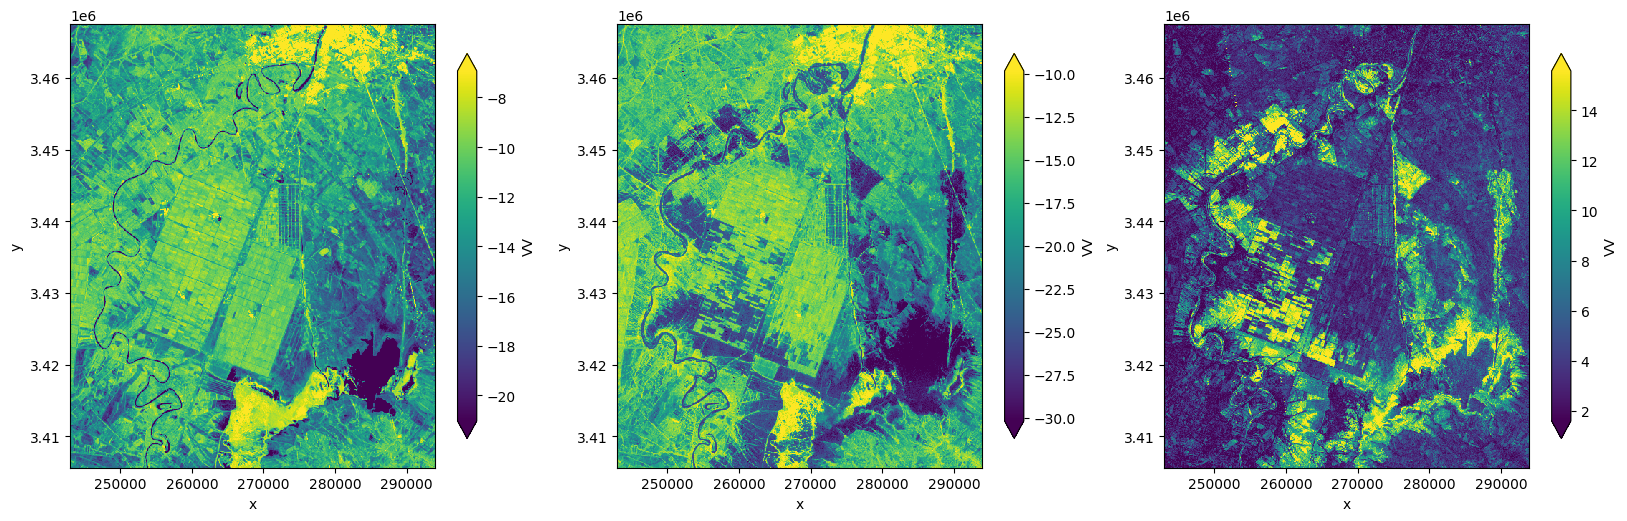

In [35]:
fig, ax = plt.subplots(1, 3, figsize = (20,10))

baseline.VV.plot(ax = ax[0], robust = True, cbar_kwargs = {'shrink': 0.5})
flood.VV.plot(ax = ax[1], robust = True, cbar_kwargs = {'shrink': 0.5})
diff.VV.plot(ax = ax[2], robust = True, cbar_kwargs = {'shrink': 0.5})

for a in ax:
  a.set_aspect('equal', adjustable = 'box')

In [36]:
from skimage.segmentation import slic

In [40]:
from scipy.ndimage import mean

In [37]:
help(slic)

Help on function slic in module skimage.segmentation.slic_superpixels:

slic(
    image,
    n_segments=100,
    compactness=10.0,
    max_num_iter=10,
    sigma=0,
    spacing=None,
    convert2lab=None,
    enforce_connectivity=True,
    min_size_factor=0.5,
    max_size_factor=3,
    slic_zero=False,
    start_label=1,
    mask=None,
    *,
    channel_axis=-1
)
    Segments image using k-means clustering in Color-(x,y,z) space.

    Parameters
    ----------
    image : (M, N[, P][, C]) ndarray
        Input image. Can be 2D or 3D, and grayscale or multichannel
        (see `channel_axis` parameter).
        Input image must either be NaN-free or the NaN's must be masked out.
    n_segments : int, optional
        The (approximate) number of labels in the segmented output image.
    compactness : float, optional
        Balances color proximity and space proximity. Higher values give
        more weight to space proximity, making superpixel shapes more
        square/cubic. In SLIC

In [43]:
segment = slic(
    diff.VV.values,
    n_segments = 1000,
    compactness = 0.1,
    sigma = 1,
    channel_axis = None,
    start_label = 1
)


mean_segment = mean(
    diff.VV.values,
    labels = segment,
    index = segment
)

flood_segment = xr.DataArray(
    mean_segment,
    dims = diff.dims,
    coords = diff.coords
)

In [49]:
from skimage.filters import threshold_otsu

In [50]:
thr = threshold_otsu(flood_segment.values)

In [52]:
flood_mask = (flood_segment >= thr).astype(int)

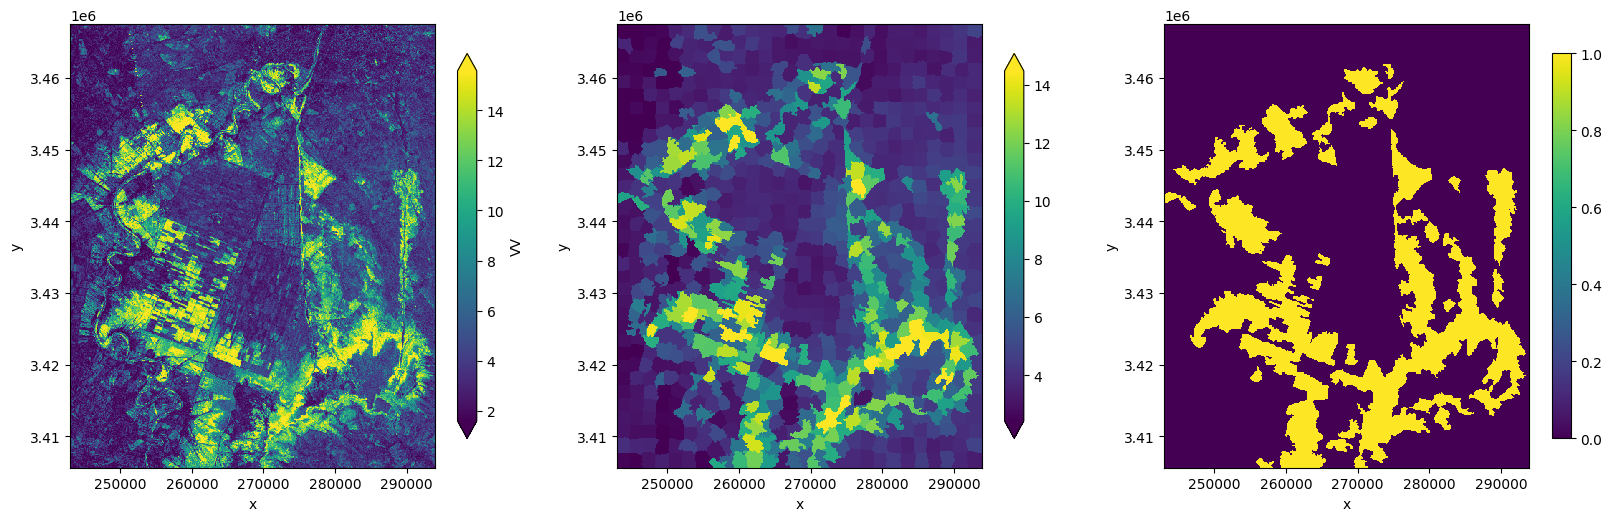

In [53]:
fig, ax = plt.subplots(1, 3, figsize =(20, 10))

diff.VV.plot(ax = ax[0], robust = True, cbar_kwargs = {'shrink':0.5})
flood_segment.plot(ax = ax[1], robust = True, cbar_kwargs = {'shrink': 0.5})
flood_mask.plot(ax = ax[2], cbar_kwargs = {'shrink': 0.5})


for a in ax:
  a.set_aspect('equal', adjustable = 'box')

In [54]:
flood_area = (flood_mask == 1).astype(int).sum(dim = ['x','y']).item() * ((100 * 100) / 1e6)
flood_area

680.61

In [55]:
no_flood_area =(flood_mask == 0).astype(int).sum(dim = ['x','y']).item() * ((100 * 100)/1e6)
no_flood_area

2470.1

In [56]:
total_area = flood_area + no_flood_area
total_area

3150.71

In [58]:
flood_pr = flood_area / total_area * 100

In [59]:
flood_pr

21.601797690044467